# LAB 06 — Attention Mechanism
Nguyễn Huy Sơn — 23001922

In [1]:
import os, re, time, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from nltk.corpus import movie_reviews
from attention_numpy import softmax, scaled_dot_product_attention
random.seed(42); np.random.seed(42); torch.manual_seed(42); torch.set_num_threads(4)


## Softmax ổn định và temperature

In [2]:
print('Softmax:', softmax([1000, 1001, 1002]))
s = np.array([4., 2., 0.])
rows = []
for t in [0.5, 1., 2.]:
    w = softmax(s / t)
    rows.append([t, w.max(), -(w * np.log(w)).sum()])
display(pd.DataFrame(rows, columns=['Temperature', 'Max weight', 'Entropy']))

Softmax: [0.09003057 0.24472847 0.66524096]


,Temperature,Max weight,Entropy
0,0.5,0.981690,0.093035
1,1.0,0.866813,0.441057
2,2.0,0.665241,0.832396


Trừ cùng một hằng số ở mọi score không làm thay đổi tỉ lệ giữa các số mũ.

## Phân phối attention theo query

,Token,Score A,Attention A,Attention B
0,The,-0.309730,0.105989,0.102694
1,movie,-1.157949,0.045382,0.057956
2,was,-0.440248,0.093020,0.106850
3,surprisingly,0.075358,0.155776,0.092786
4,good,-0.421477,0.094783,0.098435
5,despite,-0.678369,0.073310,0.112811
6,a,-0.389517,0.097861,0.090455
7,very,-0.489437,0.088555,0.191417
8,slow,-0.485284,0.088924,0.096669
9,beginning,0.079358,0.156401,0.049926


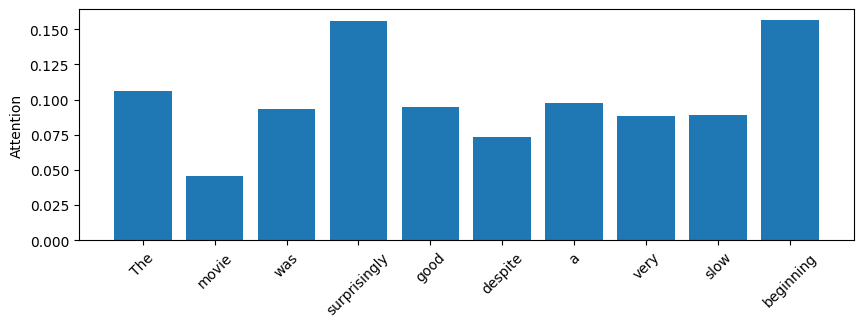

In [3]:
tokens = 'The movie was surprisingly good despite a very slow beginning'.split()
rng = np.random.default_rng(42)
K = rng.normal(size=(len(tokens), 4)); V = K.copy()
queries = rng.normal(size=(2, 4))
scores, weights, _ = scaled_dot_product_attention(queries, K, V)
display(pd.DataFrame({'Token': tokens, 'Score A': scores[0], 'Attention A': weights[0], 'Attention B': weights[1]}))
plt.figure(figsize=(10, 3)); plt.bar(tokens, weights[0]); plt.xticks(rotation=45); plt.ylabel('Attention'); plt.show()

Query thay đổi làm phân phối attention thay đổi. Vector ở đây được tạo ngẫu nhiên, không biểu diễn sentiment hay topic đã học.

## So sánh scaling
Scaling làm phân phối bớt tập trung.

In [4]:
display(pd.DataFrame({'Không scaling': softmax([4, 2, 0]), 'Scaling': softmax(np.array([4, 2, 0]) / 2)}))

,Không scaling,Scaling
0,0.866813,0.665241
1,0.117310,0.244728
2,0.015876,0.090031


## Self-attention với ba token
Đề không cung cấp giá trị cụ thể của X và các ma trận trọng số; ví dụ dưới đây tự chọn để minh họa.

Q 
 [[1. 0.]
 [0. 1.]
 [1. 1.]]
K 
 [[1. 0.]
 [0. 1.]
 [1. 1.]]
V 
 [[1. 0.]
 [0. 1.]
 [1. 1.]]
QKᵀ 
 [[1. 0. 1.]
 [0. 1. 1.]
 [1. 1. 2.]]
Attention 
 [[0.401 0.198 0.401]
 [0.198 0.401 0.401]
 [0.248 0.248 0.503]]
Context 
 [[0.802 0.599]
 [0.599 0.802]
 [0.752 0.752]]


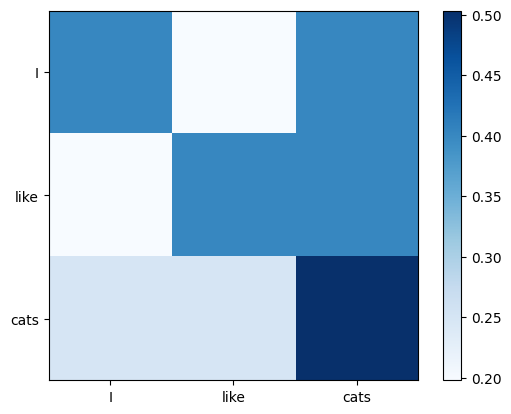

In [5]:
X = np.array([[1., 0.], [0., 1.], [1., 1.]])
Wq = np.eye(2); Wk = np.eye(2); Wv = np.eye(2)
Q, K, V = X @ Wq, X @ Wk, X @ Wv
scores, weights, context = scaled_dot_product_attention(Q, K, V)
for name, value in [('Q', Q), ('K', K), ('V', V), ('QKᵀ', Q @ K.T), ('Attention', weights), ('Context', context)]:
    print(name, '\n', np.round(value, 3))
fig, ax = plt.subplots(); im = ax.imshow(weights, cmap='Blues')
ax.set_xticks(range(3), ['I', 'like', 'cats']); ax.set_yticks(range(3), ['I', 'like', 'cats'])
fig.colorbar(im); plt.show()

## Self-attention và heatmap

cat → yesterday 0.514
adopted → cat 0.379
sleeping → I 0.297


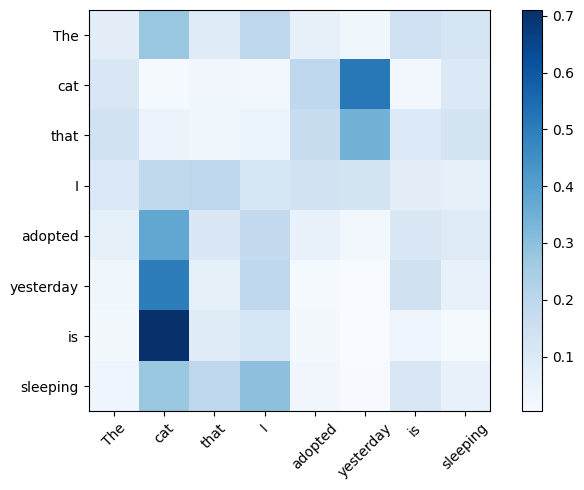

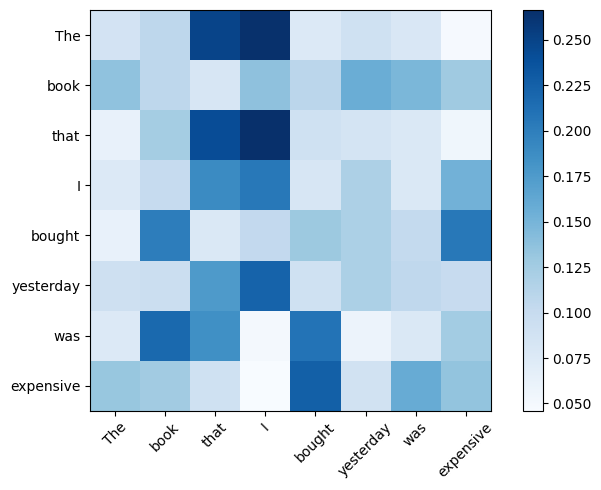

In [6]:
def random_heatmap(sentence, seed):
    tokens = sentence.replace('.', '').split()
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(len(tokens), 8))
    Wq, Wk, Wv = [rng.normal(size=(8, 8)) / np.sqrt(8) for _ in range(3)]
    _, a, context = scaled_dot_product_attention(X @ Wq, X @ Wk, X @ Wv)
    fig, ax = plt.subplots(figsize=(7, 5)); im = ax.imshow(a, cmap='Blues')
    ax.set_xticks(range(len(tokens)), tokens, rotation=45); ax.set_yticks(range(len(tokens)), tokens)
    fig.colorbar(im); fig.tight_layout(); return tokens, a, fig
for i, sentence in enumerate(['The cat that I adopted yesterday is sleeping.', 'The book that I bought yesterday was expensive.']):
    tokens, a, fig = random_heatmap(sentence, i)
    if i == 0:
        fig.savefig('attention_heatmap.png', dpi=150)
        for word in ['cat', 'adopted', 'sleeping']:
            row = a[tokens.index(word)]
            print(word, '→', tokens[row.argmax()], round(float(row.max()), 3))
    plt.show()

Heatmap dùng trọng số ngẫu nhiên, chỉ minh họa phân phối; không chứng minh mô hình hiểu ngữ pháp.

## So sánh LSTM và self-attention
Dữ liệu NLTK movie_reviews gồm 2.000 review, khác IMDb của LAB 05. Hai mô hình dùng cùng tập chia và cấu hình dưới đây.

In [7]:
documents = [(movie_reviews.raw(fid), 1 if category == 'pos' else 0) for category in ['neg', 'pos'] for fid in movie_reviews.fileids(category)]
texts, labels = zip(*documents)
train_ids, test_ids = train_test_split(np.arange(len(texts)), test_size=0.2, random_state=42, stratify=labels)
from collections import Counter
words = lambda text: re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())
counts = Counter(word for i in train_ids for word in words(texts[i]))
vocab = {word: i+2 for i, (word, _) in enumerate(counts.most_common(10000))}
MAX_LEN = 120
def encode(text):
    ids = [vocab.get(w, 1) for w in words(text)][:MAX_LEN]
    return ids + [0] * (MAX_LEN-len(ids))
X = torch.tensor([encode(t) for t in texts]); y = torch.tensor(labels, dtype=torch.float32)
def loader(ids, shuffle=False): return DataLoader(TensorDataset(X[ids], y[ids]), batch_size=64, shuffle=shuffle)
train_loader, test_loader = loader(train_ids, True), loader(test_ids)
class Classifier(nn.Module):
    def __init__(self, kind):
        super().__init__(); self.kind = kind; self.embedding = nn.Embedding(len(vocab)+2, 48, padding_idx=0)
        self.encoder = nn.LSTM(48, 48, batch_first=True) if kind == 'LSTM' else nn.Linear(48, 48 * 3)
        self.output = nn.Linear(48, 1)
    def forward(self, x, return_attention=False):
        mask = x != 0; e = self.embedding(x)
        if self.kind == 'LSTM':
            lengths = mask.sum(1).clamp(min=1).cpu()
            packed = nn.utils.rnn.pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
            _, (h, _) = self.encoder(packed); context = h[-1]; a = None
        else:
            q, k, v = self.encoder(e).chunk(3, dim=-1)
            scores = q @ k.transpose(1, 2) / np.sqrt(48)
            a = torch.softmax(scores.masked_fill(~mask[:, None, :], -1e9), dim=-1)
            h = a @ v
            context = (h * mask[:, :, None]).sum(1) / mask.sum(1, keepdim=True).clamp(min=1)
        logits = self.output(context).squeeze(-1)
        return (logits, a) if return_attention else logits


In [8]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
results, models, predictions = [], {}, {}
for kind in ['LSTM', 'Attention']:
    torch.manual_seed(42); model = Classifier(kind).to(device); opt = torch.optim.Adam(model.parameters(), lr=0.001)
    start = time.perf_counter()
    for epoch in range(4):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device); opt.zero_grad()
            loss = nn.functional.binary_cross_entropy_with_logits(model(xb), yb)
            loss.backward(); opt.step()
    if device.type == 'cuda': torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    model.eval(); probs = []
    with torch.no_grad():
        for xb, _ in test_loader: probs.extend(torch.sigmoid(model(xb.to(device))).cpu().tolist())
    pred = np.array(probs) >= 0.5; truth = y[test_ids].numpy().astype(int)
    results.append([kind, accuracy_score(truth, pred), f1_score(truth, pred), elapsed, sum(p.numel() for p in model.parameters())])
    models[kind] = model; predictions[kind] = (np.array(probs), pred)
results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'F1', 'Training time (s)', 'Parameters'])
results_df.to_csv('results.csv', index=False); display(results_df)

,Model,Accuracy,F1,Training time (s),Parameters
0,LSTM,0.5225,0.523691,0.815920,498961
1,Attention,0.5750,0.622222,0.255088,487201


LSTM dùng hidden state cuối; attention kết hợp biểu diễn giữa các token. Đây là phép thử nhỏ, chỉ chạy một seed.

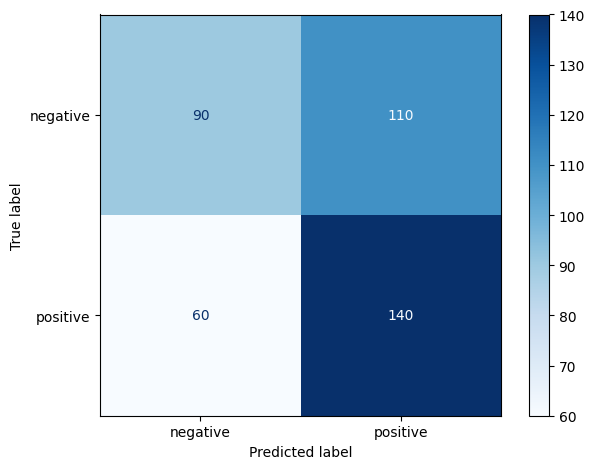

In [9]:
truth = y[test_ids].numpy().astype(int)
ConfusionMatrixDisplay(confusion_matrix(truth, predictions['Attention'][1]), display_labels=['negative', 'positive']).plot(cmap='Blues')
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=150); plt.show()

## Thử câu ngắn

I like this movie. → negative (P positive=0.264)


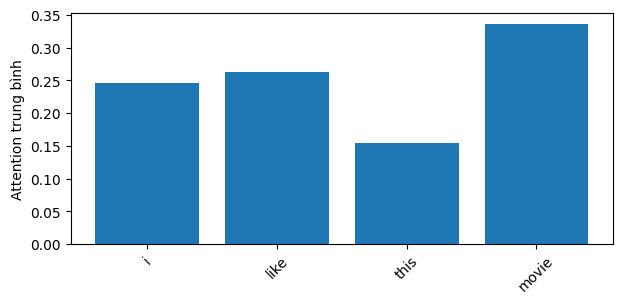

I do not like this movie. → negative (P positive=0.291)


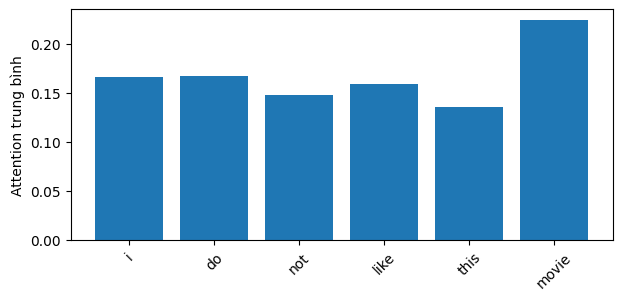

I thought this movie would be bad, but it was actually excellent. → negative (P positive=0.184)


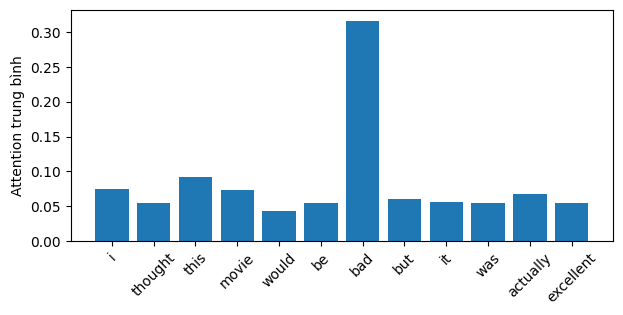

In [10]:
examples = ['I like this movie.', 'I do not like this movie.', 'I thought this movie would be bad, but it was actually excellent.']
model = models['Attention']; model.eval()
for sentence in examples:
    x = torch.tensor([encode(sentence)], device=device)
    with torch.no_grad(): logit, a = model(x, True)
    prob = torch.sigmoid(logit).item(); ts = words(sentence)[:MAX_LEN]; a = a[0, :len(ts), :len(ts)].cpu().numpy()
    print(sentence, '→', 'positive' if prob >= .5 else 'negative', f'(P positive={prob:.3f})')
    plt.figure(figsize=(7, 3)); plt.bar(ts, a.mean(axis=0)); plt.xticks(rotation=45); plt.ylabel('Attention trung bình'); plt.show()

## Các mẫu dự đoán đúng và sai

In [11]:
probs, pred = predictions['Attention']
for title, chosen in [('Đúng', np.flatnonzero(pred == truth)[:3]), ('Sai', np.flatnonzero(pred != truth)[:3])]:
    print('\n', title)
    for j in chosen:
        print('ID:', test_ids[j], '| Nhãn:', truth[j], '| Dự đoán:', int(pred[j]), '| P positive:', round(probs[j], 3))
        print(texts[test_ids[j]][:350].replace('\n', ' '))


 Đúng
ID: 20 | Nhãn: 0 | Dự đoán: 0 | P positive: 0.213
 " spawn " features good guys , bad guys , lots of fighting , bloody violence , a leather-clad machine gun chick , gooey , self-healing bullet holes , scatological humor and a man-eating monster .  it not only appears to have been tailor made for a swarm of 12- and 13-year-old boys , it appears to have been made by them .  in a classic example of t
ID: 1088 | Nhãn: 1 | Dự đoán: 1 | P positive: 0.589
the keen wisdom of an elderly bank robber , the naive ambitions of a sexy hospital nurse , and a partnership that blossoms between the two are the fine components that make up a modest , little caper adventure entitled `where the money is . '  the elderly bank robber is henry ( paul newman ) , a famous criminal that was only recently caught .  he h
ID: 466 | Nhãn: 0 | Dự đoán: 0 | P positive: 0.468
running time approximately 1hr 40mins  reviewed by jack choo  rating :  the movie starts with a rather se7en-ish opening sequence , rather

## Chi phí theo độ dài

## Attention của 3 mẫu đúng và 3 mẫu sai

In [12]:
probs, pred = predictions['Attention']
analysis_rows = []
for correct in [True, False]:
    indices = np.flatnonzero((pred == truth) == correct)[:3]
    for j in indices:
        sample_id = int(test_ids[j]); text = texts[sample_id]
        sample_words = words(text); used_words = sample_words[:MAX_LEN]
        x = torch.tensor([encode(text)], device=device)
        with torch.no_grad(): _, attention = model(x, True)
        a = attention[0, :len(used_words), :len(used_words)].cpu().numpy()
        top = np.argsort(a.mean(axis=0))[-3:][::-1]
        analysis_rows.append({'ID': sample_id, 'Đúng/sai': 'Đúng' if correct else 'Sai',
                              'Nhãn': 'positive' if truth[j] else 'negative',
                              'Dự đoán': 'positive' if pred[j] else 'negative',
                              'P positive': round(float(probs[j]), 3),
                              'Số token': len(sample_words),
                              'Attention cao': ', '.join(used_words[i] for i in top)})
analysis_df = pd.DataFrame(analysis_rows)
display(analysis_df)
analysis_df.to_csv('error_samples.csv', index=False)

,ID,Đúng/sai,Nhãn,Dự đoán,P positive,Số token,Attention cao
0,20,Đúng,negative,negative,0.213,685,"bad, then, and"
1,1088,Đúng,positive,positive,0.589,645,"naive, has, has"
2,466,Đúng,negative,negative,0.468,448,"neo, neo, and"
3,748,Sai,negative,positive,0.522,465,"and, and, and"
4,315,Sai,negative,positive,0.556,1055,"and, and, and"
5,106,Sai,negative,positive,0.569,329,"and, and, lives"


In [13]:
display(pd.DataFrame({'T': [10, 100, 500, 1000], 'Số phần tử': [t*t for t in [10, 100, 500, 1000]]}))

,T,Số phần tử
0,10,100
1,100,10000
2,500,250000
3,1000,1000000
